In [40]:
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
import subprocess as sbp
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import delayed, Parallel
from collections import Counter


def sample_configurations(
    n, k, initial_configuration=None, bias=1.0, samples=100, seed=231
):
    if initial_configuration is not None:
        icstr = f" --initial-configuration '{initial_configuration}'"
    else:
        icstr = ""

    if bias != 1.0:
        cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k}{icstr} --bias {bias} -c tabular {int(samples)}"
    else:
        cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} -c tabular {int(samples)}"

    s = sbp.getoutput(cmd).split("\n")
    return s

Text(0, 0.5, 'Frequency in the sample of 1000000 configurations')

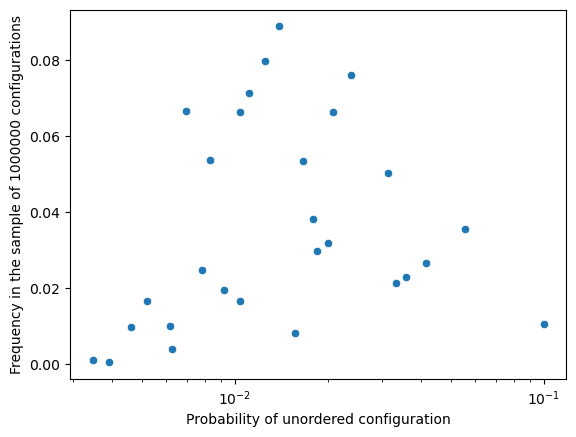

In [43]:
cs = sample_configurations(16, 7, samples=1_000_000)
cs = Counter(cs)

d = (
    pd.DataFrame([{"c": k, "cnt": v} for k, v in cs.items()])
    .sort_values("cnt")
    .reset_index(drop=True)
)
d["freq"] = d["cnt"] / d["cnt"].sum()
d["pe"] = d["c"].map(lambda c: 1 / np.prod([int(x) for x in c.split()]))
sns.scatterplot(d, x="pe", y="freq")
plt.xscale("log")
plt.xlabel("Probability of unordered configuration")
plt.ylabel("Frequency in the sample of 1000000 configurations")

Text(0.5, 1.0, '$n = 68$, $k=31$')

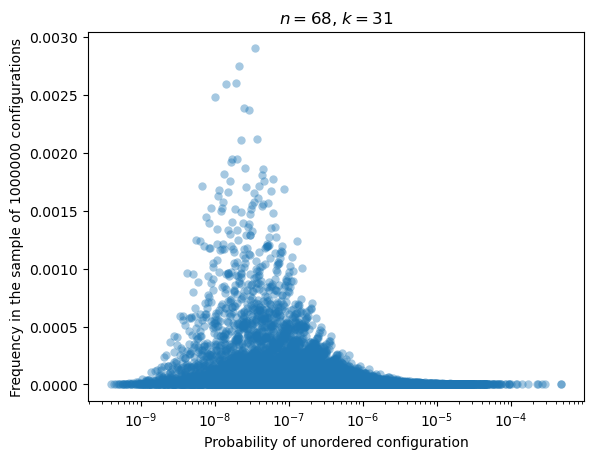

In [46]:
cs = sample_configurations(68, 31, samples=1_000_000)
cs = Counter(cs)

d = (
    pd.DataFrame([{"c": k, "cnt": v} for k, v in cs.items()])
    .sort_values("cnt")
    .reset_index(drop=True)
)
d["freq"] = d["cnt"] / d["cnt"].sum()
d["pe"] = d["c"].map(lambda c: 1 / np.prod([int(x) for x in c.split()]))
sns.scatterplot(d, x="pe", y="freq", linewidth=0, alpha=0.4)
plt.xscale("log")

plt.xlabel("Probability of unordered configuration")
plt.ylabel("Frequency in the sample of 1000000 configurations")
plt.title("$n = 68$, $k=31$")

In [45]:
d.shape

(13505, 4)